# PrivacyShield: PII Detection with DeBERTa-v3
Fine-tuning deberta-v3-small to find and mask PII in student essays.
Dataset: Kaggle "The Learning Agency Lab - PII Data Detection".

## 1. Load the data

In [ ]:
import json
path = "/kaggle/input/competitions/pii-detection-removal-from-educational-data/train.json"
with open(path) as f:
    train = json.load(f)
print(len(train))
print(train[0].keys())
print(train[0]["tokens"][:15])
print(train[0]["labels"][:15])

6807
dict_keys(['document', 'full_text', 'tokens', 'trailing_whitespace', 'labels'])
['Design', 'Thinking', 'for', 'innovation', 'reflexion', '-', 'Avril', '2021', '-', 'Nathalie', 'Sylla', '\n\n', 'Challenge', '&', 'selection']
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-NAME_STUDENT', 'I-NAME_STUDENT', 'O', 'O', 'O', 'O']


## 2. Label counts (how rare is PII?)

In [ ]:
from collections import Counter
c = Counter(l for doc in train for l in doc["labels"])
for label, n in c.most_common():
    print(f"{label:20s} {n}")

O                    4989794
B-NAME_STUDENT       1365
I-NAME_STUDENT       1096
B-URL_PERSONAL       110
B-ID_NUM             78
B-EMAIL              39
I-STREET_ADDRESS     20
I-PHONE_NUM          15
B-USERNAME           6
B-PHONE_NUM          6
B-STREET_ADDRESS     2
I-URL_PERSONAL       1
I-ID_NUM             1


## 3. Data exploration: PII types and essay length

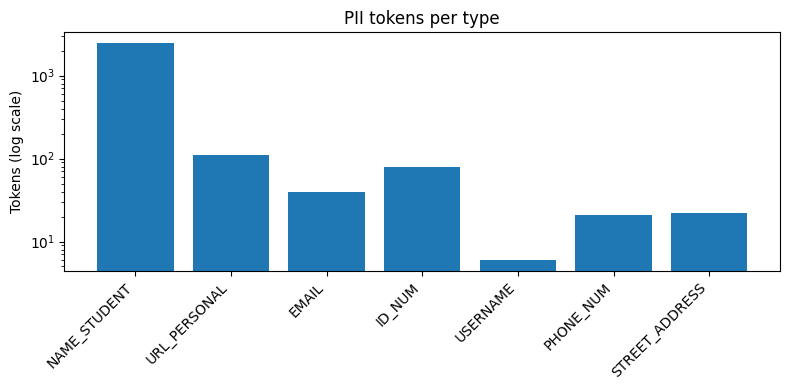

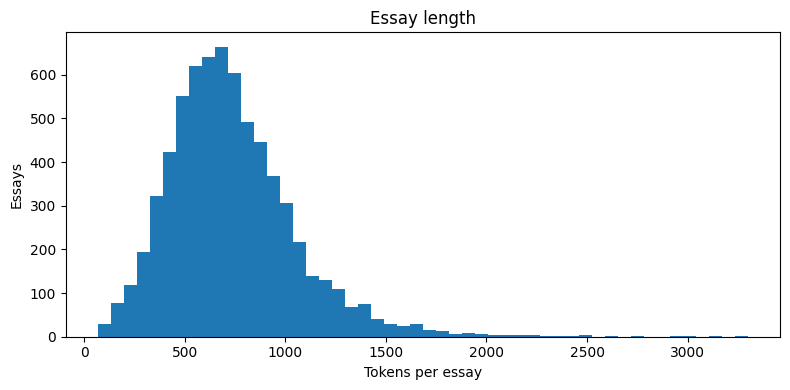

Essays with PII: 945 of 6807
Average length: 733 | Max: 3298
Essays longer than 512 tokens: 5171


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Chart 1: PII types (B- aur I- ko jama karke)
types = Counter()
for doc in train:
    for l in doc["labels"]:
        if l != "O":
            types[l.split("-", 1)[1]] += 1

plt.figure(figsize=(8, 4))
plt.bar(types.keys(), types.values())
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Tokens (log scale)")
plt.title("PII tokens per type")
plt.tight_layout()
plt.savefig("pii_types.png", dpi=150)
plt.show()

# Chart 2: essay length
lengths = [len(doc["tokens"]) for doc in train]
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=50)
plt.xlabel("Tokens per essay")
plt.ylabel("Essays")
plt.title("Essay length")
plt.tight_layout()
plt.savefig("essay_length.png", dpi=150)
plt.show()

# Numbers for the README
with_pii = sum(any(l != "O" for l in doc["labels"]) for doc in train)
print("Essays with PII:", with_pii, "of", len(train))
print("Average length:", int(np.mean(lengths)), "| Max:", max(lengths))
print("Essays longer than 512 tokens:", sum(l > 512 for l in lengths))

## 4. Prepare data: tokenize, align labels, split into chunks

In [ ]:
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

MODEL = "microsoft/deberta-v3-small"
MAX_LEN, STRIDE = 512, 128

tokenizer = AutoTokenizer.from_pretrained(MODEL)

# labels: "O" pehle
all_labels = sorted({l for d in train for l in d["labels"]} - {"O"})
all_labels = ["O"] + all_labels
label2id = {l: i for i, l in enumerate(all_labels)}
id2label = {i: l for l, i in label2id.items()}
print("Number of labels:", len(all_labels))

# split by essay
has_pii = [any(l != "O" for l in d["labels"]) for d in train]
train_docs, val_docs = train_test_split(
    train, test_size=0.15, random_state=42, stratify=has_pii
)
print("Train essays:", len(train_docs), "| Val essays:", len(val_docs))

def make_chunks(docs):
    chunks = []
    for d in docs:
        enc = tokenizer(
            d["tokens"], is_split_into_words=True,
            truncation=True, max_length=MAX_LEN,
            stride=STRIDE, return_overflowing_tokens=True,
        )
        for i in range(len(enc["input_ids"])):
            word_ids = enc.word_ids(i)
            labs, prev = [], None
            for w in word_ids:
                if w is None or w == prev:
                    labs.append(-100)          # special token or sub-word
                else:
                    labs.append(label2id[d["labels"][w]])
                prev = w
            chunks.append({
                "input_ids": enc["input_ids"][i],
                "attention_mask": enc["attention_mask"][i],
                "labels": labs,
            })
    return chunks

train_chunks = make_chunks(train_docs)
val_chunks = make_chunks(val_docs)

def has_label(c):
    return any(l > 0 for l in c["labels"])

print("Train chunks:", len(train_chunks), "| with PII:", sum(map(has_label, train_chunks)))
print("Val chunks:", len(val_chunks), "| with PII:", sum(map(has_label, val_chunks)))

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Number of labels: 13
Train essays: 5785 | Val essays: 1022
Train chunks: 11546 | with PII: 984
Val chunks: 2026 | with PII: 185


## 5. Train the model (negative sampling, 3 epochs)

In [ ]:
import random, numpy as np, torch
from datasets import Dataset
from transformers import (AutoModelForTokenClassification, TrainingArguments,
                          Trainer, DataCollatorForTokenClassification)

random.seed(42)

# negative sampling
pos = [c for c in train_chunks if has_label(c)]
neg = [c for c in train_chunks if not has_label(c)]
train_small = pos + random.sample(neg, int(len(neg) * 0.25))
random.shuffle(train_small)
print("Training chunks:", len(train_small))

train_ds = Dataset.from_list(train_small)
val_ds = Dataset.from_list(val_chunks)

model = AutoModelForTokenClassification.from_pretrained(
    MODEL, num_labels=len(all_labels), id2label=id2label, label2id=label2id
)
model = model.float()   # FIX: weights ko float32 mein karo

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    mask = labels != -100
    p, t = preds[mask], labels[mask]
    tp = ((p == t) & (t != 0)).sum()
    fp = ((p != 0) & (p != t)).sum()
    fn = ((t != 0) & (p != t)).sum()
    prec = tp / (tp + fp + 1e-9)
    rec = tp / (tp + fn + 1e-9)
    f5 = 26 * prec * rec / (25 * prec + rec + 1e-9)
    return {"precision": float(prec), "recall": float(rec), "f5": float(f5)}

args = TrainingArguments(
    output_dir="/kaggle/working/pii-deberta-small",
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=130,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f5",
    logging_steps=50,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorForTokenClassification(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()
trainer.save_model("/kaggle/working/pii-deberta-small-final")

Training chunks: 3624


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different tas

Epoch,Training Loss,Validation Loss,Precision,Recall,F5
1,0.004329,0.001475,0.851064,0.753138,0.756486
2,0.001864,0.001320,0.775238,0.851464,0.848257
3,0.000919,0.001523,0.716239,0.876569,0.869087


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 6. Evaluation: threshold tuning and per-type scores

In [ ]:
import numpy as np, pandas as pd
from scipy.special import softmax

out = trainer.predict(val_ds)
probs = softmax(out.predictions, axis=-1)
labels = out.label_ids
mask = labels != -100
P, T = probs[mask], labels[mask]          # P: (tokens, 13), T: true label ids

def f5_score(pred, true):
    tp = ((pred == true) & (true != 0)).sum()
    fp = ((pred != 0) & (pred != true)).sum()
    fn = ((true != 0) & (pred != true)).sum()
    prec = tp / (tp + fp + 1e-9)
    rec = tp / (tp + fn + 1e-9)
    f5 = 26 * prec * rec / (25 * prec + rec + 1e-9)
    return prec, rec, f5

def predict_with_thr(P, thr):
    non_o = P[:, 1:].argmax(1) + 1
    return np.where(P[:, 0] < thr, non_o, 0)

# 1) Threshold sweep
rows = []
for thr in [0.5, 0.7, 0.9, 0.95, 0.99, 0.995, 0.999]:
    p, r, f = f5_score(predict_with_thr(P, thr), T)
    rows.append({"threshold": thr, "precision": round(p, 3), "recall": round(r, 3), "f5": round(f, 3)})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))
best_thr = sweep.loc[sweep["f5"].idxmax(), "threshold"]
print("\nBest threshold:", best_thr)

# 2) Per-type results at the best threshold
pred = predict_with_thr(P, best_thr)
types = sorted({l.split("-", 1)[1] for l in all_labels if l != "O"})
rows = []
for ty in types:
    ids = [label2id[l] for l in all_labels if l != "O" and l.endswith(ty)]
    t, p = np.isin(T, ids), np.isin(pred, ids)
    tp, fp, fn = (t & p).sum(), (~t & p).sum(), (t & ~p).sum()
    prec = tp / (tp + fp + 1e-9)
    rec = tp / (tp + fn + 1e-9)
    f5 = 26 * prec * rec / (25 * prec + rec + 1e-9)
    rows.append({"type": ty, "support": int(t.sum()), "precision": round(prec, 3),
                 "recall": round(rec, 3), "f5": round(f5, 3)})
per_type = pd.DataFrame(rows)
print("\n", per_type.to_string(index=False))

sweep.to_csv("/kaggle/working/threshold_sweep.csv", index=False)
per_type.to_csv("/kaggle/working/per_type_results.csv", index=False)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


 threshold  precision  recall    f5
     0.500      0.699   0.883 0.874
     0.700      0.628   0.904 0.889
     0.900      0.547   0.937 0.912
     0.950      0.519   0.950 0.920
     0.990      0.436   0.958 0.916
     0.995      0.400   0.962 0.913
     0.999      0.301   0.964 0.889

Best threshold: 0.95

           type  support  precision  recall    f5
         EMAIL       13      0.929   1.000 0.997
        ID_NUM        8      0.304   0.875 0.816
  NAME_STUDENT      416      0.560   0.983 0.955
     PHONE_NUM        8      0.267   0.500 0.484
STREET_ADDRESS       10      0.500   0.100 0.103
  URL_PERSONAL       21      0.233   1.000 0.888
      USERNAME        2      0.000   0.000 0.000


## 7. Sanity check on a real validation essay

In [ ]:
import torch

m = trainer.model
m.eval()

def word_probs(words):
    enc = tokenizer(words, is_split_into_words=True, truncation=True,
                    max_length=512, return_tensors="pt").to(m.device)
    with torch.no_grad():
        logits = m(**enc).logits[0]
    probs = torch.softmax(logits.float(), -1).cpu().numpy()
    res, prev = {}, None
    for i, w in enumerate(enc.word_ids(0)):
        if w is not None and w != prev:
            res[w] = probs[i]
        prev = w
    return res

def p_not_pii(wp, i):
    return wp[i][0] if i in wp else 1.0   # words with no tokens count as "not PII"

# a real validation essay that contains PII
doc = next(d for d in val_docs if any(l != "O" for l in d["labels"]))
first = next(i for i, l in enumerate(doc["labels"]) if l != "O")
start = max(0, first - 100)
words = doc["tokens"][start:start + 300]
labs = doc["labels"][start:start + 300]

wp = word_probs(words)
true_pii = [(w, l) for w, l in zip(words, labs) if l != "O"]

for thr in [0.5, 0.95]:
    flagged = [w for i, w in enumerate(words) if p_not_pii(wp, i) < thr]
    print(f"threshold {thr}: flagged {len(flagged)} of {len(words)} words")
    print("   ", flagged[:30])

print("\nTRUE PII in this window:", true_pii)

# the short sentence from before, with P(not PII) per word
s = "My name is Sara Ali and my email is sara.ali@gmail.com".split()
sp = word_probs(s)
print()
for i, w in enumerate(s):
    print(f"{w:22s} P(not PII) = {p_not_pii(sp, i):.3f}")

threshold 0.5: flagged 2 of 300 words
    ['Akhilesh', 'Kumar']
threshold 0.95: flagged 2 of 300 words
    ['Akhilesh', 'Kumar']

TRUE PII in this window: [('Akhilesh', 'B-NAME_STUDENT'), ('Kumar', 'I-NAME_STUDENT')]

My                     P(not PII) = 0.724
name                   P(not PII) = 0.820
is                     P(not PII) = 0.655
Sara                   P(not PII) = 0.002
Ali                    P(not PII) = 0.002
and                    P(not PII) = 0.554
my                     P(not PII) = 0.692
email                  P(not PII) = 0.872
is                     P(not PII) = 0.795
sara.ali@gmail.com     P(not PII) = 0.011


## 8. Redaction demo

In [ ]:
CONTEXT = ("In my reflection I learned that design thinking helps us solve problems step by step . "
           "First we talk to people , then we try ideas , and finally we test them in class .").split()

def redact(text, thr=0.5, use_context=True):
    words = text.split()
    ctx = CONTEXT if use_context else []
    wp = word_probs(ctx + words)

    out, last_type = [], None
    for i, w in enumerate(words):
        j = i + len(ctx)
        if j not in wp or wp[j][0] >= thr:
            out.append(w); last_type = None
        else:
            lab = id2label[int(wp[j][1:].argmax()) + 1]
            ty = lab.split("-", 1)[1]
            if ty != last_type or lab.startswith("B-"):
                out.append(f"[{ty}]")
            last_type = ty
    return " ".join(out)

tests = [
    "My name is Sara Ali and my email is sara.ali@gmail.com",
    "Hello, I am Nathalie Sylla from Paris. You can visit my site at https://nathalie.me",
    "Contact Ahmed Khan on 0300-1234567 about the project.",
    "The weather was nice and we walked to the park after class.",
]
for t in tests:
    print("IN               :", t)
    print("0.5, no context  :", redact(t, 0.5, False))
    print("0.5, context     :", redact(t, 0.5, True))
    print("0.9, context     :", redact(t, 0.9, True), "\n")

IN               : My name is Sara Ali and my email is sara.ali@gmail.com
0.5, no context  : My name is [NAME_STUDENT] and my email is [EMAIL]
0.5, context     : My name is [NAME_STUDENT] and my email is [EMAIL]
0.9, context     : My name is [NAME_STUDENT] and my email is [EMAIL] 

IN               : Hello, I am Nathalie Sylla from Paris. You can visit my site at https://nathalie.me
0.5, no context  : Hello, I am [NAME_STUDENT] from Paris. You can visit my site at [URL_PERSONAL]
0.5, context     : Hello, I am [NAME_STUDENT] from Paris. You can visit my site at [URL_PERSONAL]
0.9, context     : Hello, I am [NAME_STUDENT] from Paris. You can visit my site at [URL_PERSONAL] 

IN               : Contact Ahmed Khan on 0300-1234567 about the project.
0.5, no context  : Contact [NAME_STUDENT] on [ID_NUM] about the project.
0.5, context     : Contact [NAME_STUDENT] on [ID_NUM] about the project.
0.9, context     : Contact [NAME_STUDENT] [URL_PERSONAL] [ID_NUM] about the project. 

IN          